# CA1 - Data Visualisation and Communication
## LUIS RAMIREZ - 2023169

**Tech jobs in the US**

Employment statistics for the USA as of May 2023 in fields like AI, Data Science and Software Development.

### **1. LIBRARIES**

In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### **2. LOADING THE DATA**

The original file is an Excel file and is very slow to open (my firt try even had to be stopped). To fix that I convert it to a CSV one time and then I always read the CSV, which is much faster.
The cell below checks if the CSV already exists, so it safe to run mote than once. It only does the slow conversion the first time.

In [2]:
## Changing the format file to a CSV

FOLDER = r'C:\Users\felip\Documents\CA-DataVisual' # This is the folder where the files will be.
XLSX_PATH = os.path.join(FOLDER, "all_data_M_2023.xlsx")
CSV_PATH = os.path.join(FOLDER, "all_data_M_2023.csv")

# Only convert if the CSV is not there yet
if not os.path.exists(CSV_PATH):
    print("( (!) CSV not found, converting the Excel file (this can take a few minutes)...")
    pd.read_excel(XLSX_PATH).to_csv(CSV_PATH, index=False)
    print("Done!")
else:
    print("======> CSV already exists, nothing to convert <======")


======> CSV already exists, nothing to convert <======


Once I have the new CSV file, I can read it into df. I am going to use low_memory=False because pandas was giving me a DtypeWarning because some columns have numbers and symbols mixed, like * and #. With this option enabled, pandas reads the whole column before choosing the type, so the warnings go away.

In [3]:
df = pd.read_csv(CSV_PATH, low_memory=False)

print("Rows:", df.shape[0], "| columns:", df.shape[1])
df.head()

Rows: 413327 | columns: 32


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## Running the new CSV file for this project

In [4]:
### Adding the new CSV DataFrame to df.
### With a new CSV file, the process will be faster.
csv_file = r"C:\Users\felip\Documents\CA-DataVisual\all_data_M_2023.csv"
df= pd.read_csv(csv_file)
df.head() #prove of the dataset working

C:\Users\felip\AppData\Local\Temp\ipykernel_46436\1920427162.py:4: DtypeWarning: Columns (4,13,14,15,16,30,31) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv(csv_file)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


## Dealing with Missing Data ##

In [5]:
df.isnull().sum()

AREA                 0
AREA_TITLE           0
AREA_TYPE            0
PRIM_STATE           0
NAICS                0
NAICS_TITLE          0
I_GROUP              0
OWN_CODE             0
OCC_CODE             0
OCC_TITLE            0
O_GROUP              0
TOT_EMP              0
EMP_PRSE             0
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN               0
A_MEAN               0
MEAN_PRSE            0
H_PCT10              0
H_PCT25              0
H_MEDIAN             0
H_PCT75              0
H_PCT90              0
A_PCT10              0
A_PCT25              0
A_MEDIAN             0
A_PCT75              0
A_PCT90              0
ANNUAL          396830
HOURLY          412572
dtype: int64

In [6]:
# Based on the information provided in the Excel file:
# '*'  = indicates that a wage estimate is not available
# '**'  = indicates that an employment estimate is not available
# '#'  = indicates a wage equal to or greater than $115.00 per hour or $239,200 per year
# '~' = indicates that the percent of establishments reporting the occupation is less than 0.5%

### STEP 1 ###
# Finding symbols to replace it
symbols = ['#', '*', '**', '~'] # Matching simbols.
df_str = df.astype(str).apply(lambda col: col.str.strip()) #  Turns every value in the table into text.
sym_table = pd.DataFrame({sym: (df_str == sym).sum() for sym in symbols}) # Compares every cell with one of the symbols
sym_table[(sym_table > 0).any(axis=1)] # Gives True if the symbols appear at least once.

,#,*,**,~
TOT_EMP,0,0,11598,0
EMP_PRSE,0,0,11598,0
JOBS_1000,0,0,3633,0
LOC_QUOTIENT,0,0,3633,0
PCT_TOTAL,0,0,7886,0
PCT_RPT,0,0,7886,52694
H_MEAN,269,20695,0,0
A_MEAN,269,5083,0,0
MEAN_PRSE,0,4431,0,0
H_PCT10,269,20695,0,0


In [7]:
### STEP 2 ###
# Converting symbols to NaN (so they count as missing from now on)
num_cols = ['TOT_EMP','H_MEAN','A_MEAN','H_PCT10','H_PCT25','H_MEDIAN','H_PCT75','H_PCT90',
            'A_PCT10','A_PCT25','A_MEDIAN','A_PCT75','A_PCT90']
for c in num_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '').str.strip(), errors='coerce')

df[num_cols].isnull().sum()


### Run STEP 1 and STEP 2 again after this, and the counts will no include the symbols values.

TOT_EMP     11598
H_MEAN      20964
A_MEAN       5352
H_PCT10     20964
H_PCT25     21426
H_MEDIAN    23059
H_PCT75     26119
H_PCT90     33008
A_PCT10      5353
A_PCT25      5815
A_MEDIAN     7474
A_PCT75     10606
A_PCT90     17844
dtype: int64

### **3. MISSING DATA**

First, I have to count the missing values in every column

In [8]:
missing = df.isnull().sum()
missing[missing >0] # Only show the columns that have missing values

TOT_EMP          11598
JOBS_1000       177501
LOC_QUOTIENT    177501
PCT_TOTAL       242857
PCT_RPT         242857
H_MEAN           20964
A_MEAN            5352
H_PCT10          20964
H_PCT25          21426
H_MEDIAN         23059
H_PCT75          26119
H_PCT90          33008
A_PCT10           5353
A_PCT25           5815
A_MEDIAN          7474
A_PCT75          10606
A_PCT90          17844
ANNUAL          396830
HOURLY          412572
dtype: int64

Some columns too many missing values ( for example PCT_TOTAL and PCT_RPT), but this count is not the full story. The Excel file says that the data uses spacial symbols instead of numbers in some cells:
| Symbol | Meaning |
|---|---|
| `*` | wage estimate not available |
| `**` | employment estimate not available |
| `#` | wage is $115.00/hour or $239,200/year **or more** |
| `~` | less than 0.5% of establishments report this occupation |

So some columns have symbols hidden in them that pandas does not count as missing. 

###         *3.1 Finding the symbols in the dataset*

In [9]:
symbols = ['#', '*', '**', '~']

# Turn everything into tex, and remove spaces, so I can compare with the symbols.
df_str = df.astype(str).apply(lambda col: col.str.strip())

# for each symbol, count how many time it shows up in each column
sym_table = pd.DataFrame({sym: (df_str ==sym).sum() for sym in symbols})

# show only the columns where at least one symbol appear
sym_table[(sym_table >0).any(axis=1)]

,#,*,**,~
EMP_PRSE,0,0,11598,0
JOBS_1000,0,0,3633,0
LOC_QUOTIENT,0,0,3633,0
PCT_TOTAL,0,0,7886,0
PCT_RPT,0,0,7886,52694
MEAN_PRSE,0,4431,0,0


the symbols appear in TOT_EMP, EMP_PRSE, JOBS_1000, LOC_QUOTIENT, PCT_TOTAL, PCT_RPT, H_MEAN, A_MEAN, MEAN_PRSE, H_PCT10, H_PCT25, H_MEDIAN, H_PCT75, H_PCT90, A_PCT10, A_PCT25, A_MEDIAN, A_PCT75, and A_PCT90.
Next, I need to fix the numeric columns that I am going to use (employment and wages)

###         *3.2 Turn the symbols into NaN*

The wage and employment columns have symbols in them, so pandas reads them as text. Whith the function pd.to_ numeric(..., errors='coerce') every value that is not a real number becomes NaN, and I will remove commmas first, for example '1,234,567'.

In [10]:
num_cols = ['TOT_EMP', 'H_MEAN', 'A_MEAN', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90',
            'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90']

for c in num_cols:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',','').str.strip(),errors='coerce')

# Missing values now include the symbols
df[num_cols].isnull().sum()

TOT_EMP     11598
H_MEAN      20964
A_MEAN       5352
H_PCT10     20964
H_PCT25     21426
H_MEDIAN    23059
H_PCT75     26119
H_PCT90     33008
A_PCT10      5353
A_PCT25      5815
A_MEDIAN     7474
A_PCT75     10606
A_PCT90     17844
dtype: int64

In [11]:
df.head() # With this function, I can quickly check the results.

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.40,29050.0,35660.0,48060.0,76980.0,121470.0,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550.0,78330.0,116880.0,169090.0,231620.0,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,NaN,46400.0,66170.0,103460.0,165500.0,NaN,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,NaN,NaN,80000.0,130840.0,206680.0,NaN,NaN,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,NaN,NaN,80000.0,130840.0,206680.0,NaN,NaN,NaN,NaN


Now the counts include the symbols too, so they are the real numbers of missing values. I don't delete rows with missing values from the whole dataset, as that would remove too much data; instead, I drop NaN values only in the specific column I use for each chart.

### **4. CHOOSING THE TECH OCCUPATIONS**

The dataset has hundred of occupations, so I keep only the tech ones using their SOC 2019 codes*, and I also make three smaller tables:

- `us` : national totals (`AREA_TYPE = 1`)
- `states` : state rows (`AREA_TYPE = 2`)
- `metro` : metro area rows (`AREA_TYPE = 4`)

I only use the Cross-industry rows so I don't count the same workers twice.

\**The 6-digit Standard Occupational Classification (SOC) code or OEWS-specific code for the occupation*

In [12]:
tech_codes = {
    '15-1221': 'Computer & Info Research Scientists',
    '15-2051': 'Data Scientists',
    '15-1252': 'Software Developers',
    '15-1251': 'Computer Programmers',
    '15-1253': 'Software QA Analysts & Testers',
    '15-1211': 'Computer Systems Analysts',
    '15-1212': 'Information Security Analysts',
    '15-1242': 'Database Administrators',
    '15-1243': 'Database Architects',
    '15-1255': 'Web & Digital Interface Designers',
    '15-2031': 'Operations Research Analysts',
    '15-2041': 'Statisticians',
}
df['OCC_CODE'] = df['OCC_CODE'].astype(str).str.strip()
tech = df[
    df['OCC_CODE'].isin(tech_codes)
    & (df['NAICS_TITLE'] == 'Cross-industry')   # avoid double counting industries
].copy()
tech['OCC_SHORT'] = tech['OCC_CODE'].map(tech_codes)

us     = tech[tech['AREA_TYPE'] == 1].copy()
states = tech[tech['AREA_TYPE'] == 2].copy()
metro  = tech[tech['AREA_TYPE'] == 4].copy()

us[['OCC_SHORT','TOT_EMP','A_MEDIAN']]

,OCC_SHORT,TOT_EMP,A_MEDIAN
135,Computer Systems Analysts,498810.0,103800.0
136,Information Security Analysts,175350.0,120360.0
138,Computer & Info Research Scientists,35210.0,145080.0
144,Database Administrators,76140.0,101510.0
145,Database Architects,59920.0,134700.0
148,Computer Programmers,120370.0,99700.0
149,Software Developers,1656880.0,132270.0
150,Software QA Analysts & Testers,203040.0,101800.0
152,Web & Digital Interface Designers,111060.0,98540.0
161,Operations Research Analysts,117880.0,83640.0


I get 12 national rows, one per occupation.

### **5. OUTLIERS**

I use the **IQR rule** per occupation: a value is an outlier if it is:

- below `Q1 - 1.5*IQR` or
- above `Q3 + 1.5*IQR`.
  
I apply it to the annual median salary (`A_MEDIAN`) across metro areas, because that is where extreme values are most likely (e.g. San Francisco or San Jose vs. small cities).

Note: the `#` symbol (wage >= $239,200) was converted to NaN earlier. Those are *top-coded*, not missing at random, so I drop NaNs only for the specific column I am plotting and I keep in mind that the highest salaries are slightly under-represented.

In [13]:
def flag_outliers(group, col='A_MEDIAN'):
    q1, q3 = group[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    group = group.copy()
    group['IS_OUTLIER'] = (group[col] < low) | (group[col] > high)
    return group

metro_valid = metro.dropna(subset=['A_MEDIAN', 'TOT_EMP'])
metro_flagged = (metro_valid.groupby('OCC_SHORT', group_keys=False)
                            .apply(flag_outliers))

print(metro_flagged.groupby('OCC_SHORT')['IS_OUTLIER'].agg(['sum', 'count']))

# Cleaned version with no outliers used only where extreme values would hide the main pattern
metro_clean = metro_flagged[~metro_flagged['IS_OUTLIER']]
print("Rows before:", len(metro_flagged), "| after removing outliers:", len(metro_clean))

                                     sum  count
OCC_SHORT                                      
Computer & Info Research Scientists    5     64
Computer Programmers                   9    230
Computer Systems Analysts              5    360
Data Scientists                        3    242
Database Administrators                3    197
Database Architects                    7    128
Information Security Analysts         17    225
Operations Research Analysts           2    184
Software Developers                    9    378
Software QA Analysts & Testers         7    213
Statisticians                          1     90
Web & Digital Interface Designers     12    172
Rows before: 2483 | after removing outliers: 2403


C:\Users\felip\AppData\Local\Temp\ipykernel_46436\360564786.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(flag_outliers))


### **6. VISUALISATIONS**

##### **6.1 Employment by occupation (USA) - BAR CHART**

**Objective:** In this first visualisation, I am going to compare which tech occupation employs the most people.

**Why this visualisation:** With one categorical variable (occupation) against one numeric variable (employment), a horizontal bar chart is the clearest way to compare sizes, and long occupation names stay readable.

**What I learned about AI employment from this:** Software developers are by far the largest tech occupation in the US in 2023, but in 2023, AI was still a smaller part of the workforce industry. With a bout 1.6 million workers, it is more than three times the second one (Computer Systems Analyst). On the other hand, the more "advanced" jobs are really small, for example, computer and research scientists with only about 35.000.

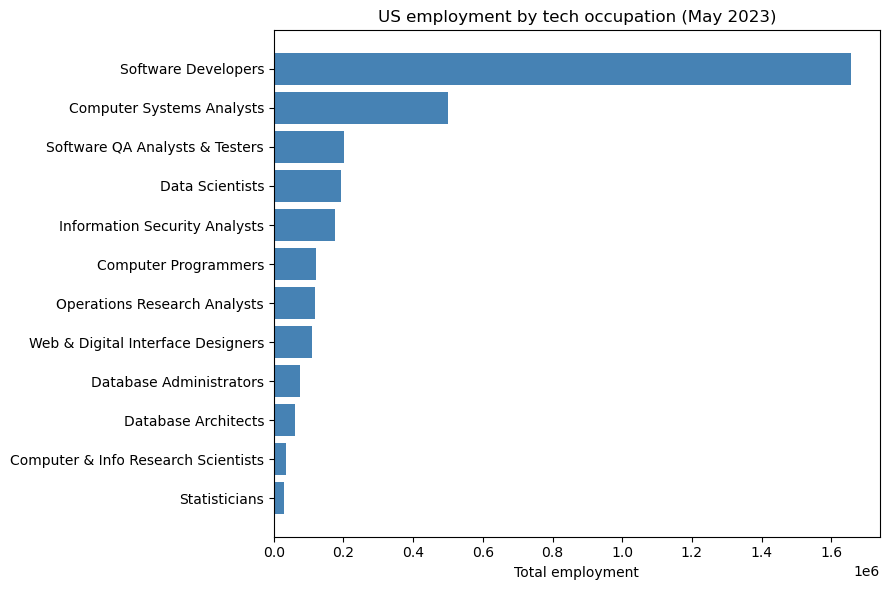

In [14]:
d = us.sort_values('TOT_EMP')
plt.figure(figsize=(9, 6))
plt.barh(d['OCC_SHORT'], d['TOT_EMP'], color='steelblue')
plt.xlabel('Total employment')
plt.title('US employment by tech occupation (May 2023)')
plt.tight_layout()
plt.show()

##### **6.2  Share of tech employment (USA) - PIE CHART**

**Objective:** In this visualisation, I am going to represent each job's share percentage of the tech industry in the USA.

**Why this visualisation:** The pie chart is the most optimal graphic representation of the total share per job or occupation in an industry. A pie chart is only readable with a few slices, so I am going to group every occupation with less than 5% into one slice called Other. 

**What I learned about AI employment from this:** Software developers alone are about half (50,6%) of all tech jobs. This representation represents how important the Software Development role is for the tech industry. The job most related to AI in 2023 was Data Scientists, and it is only 5,9% of the total industry.

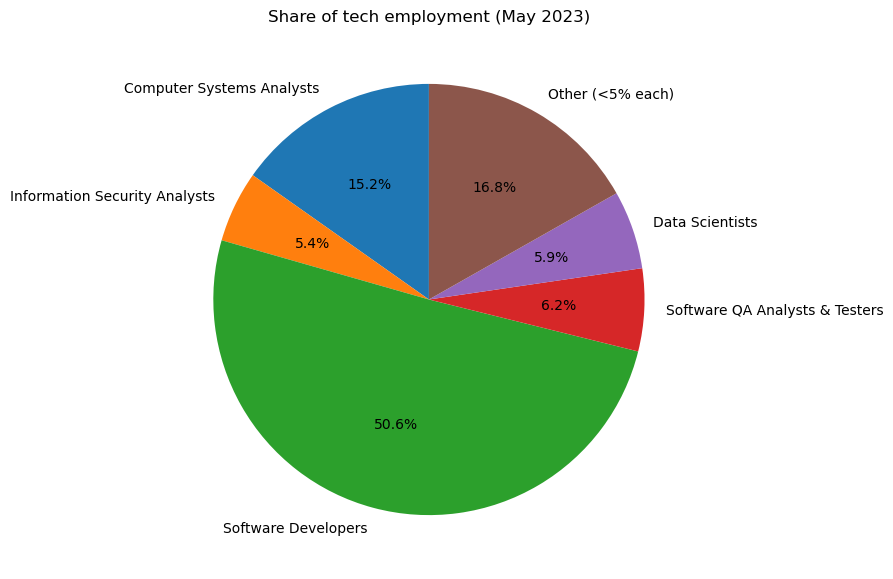

In [15]:
share = us.set_index('OCC_SHORT')['TOT_EMP']
pct = share / share.sum()
small = pct[pct < 0.05].sum()
pie_data = share[pct >= 0.05].copy()
pie_data['Other (<5% each)'] = share[pct < 0.05].sum()

plt.figure(figsize=(7, 7))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', startangle=90)
plt.title('Share of tech employment (May 2023)')
plt.show()

##### **6.3  Range Chart for salary ranges for AI, Data Science and Software jobs (USA) - RANGE CHART**

**Objective:** In this visualisation, I am going to do a comparison and distribution of how much people in each job earn, not only the median value but also the low percentile and the high percentile (the 90th).

**Why this visualisation:** The dumbbell/range chart shows the whole spread in one line per job, and a normal bar chart would only show one number (the median), that is why this chart is the best option. 

**What I learned about AI employment from this:** The AI/Rersearch jobs, like computer and information research scientist, and software developers are at the top for pay, with medians well above the average US job. Some jobs like web developers and QA testers earn clearly less. The lines are also quite long, so what people earn inside the same job varies a lot, and in general, AI-related roles are some of the best-paid roles in the whole computer area.

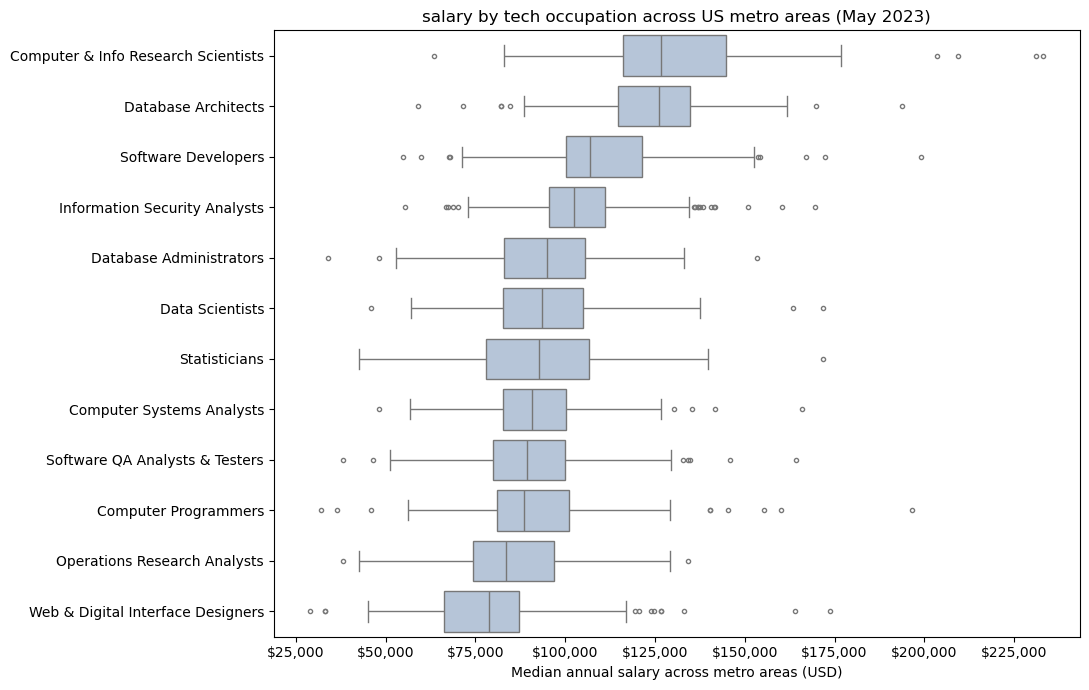

In [20]:
# Order the occupations from the highest to the lowest media salary
order = (metro_flagged.groupby('OCC_SHORT')['A_MEDIAN']
                      .median()
                      .sort_values(ascending=False)
                      .index)

fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=metro_flagged, y='OCC_SHORT', x='A_MEDIAN', order=order,
            color='lightsteelblue', fliersize=3, ax=ax)

ax.set_xlabel('Median annual salary across metro areas (USD)')
ax.set_ylabel('')

ax.set_title('salary by tech occupation across US metro areas (May 2023)')
ax.xaxis.set_major_formatter(lambda x, pos: f"${x:,.0f}")
plt.tight_layout()
plt.show()
